# PathSnap — Model 1: Logistic Regression (executed)
**Owner:** Pradeep

CV: 5-fold GroupKFold by trip on 80 train trips. Test: 10 student_test trips. Primary metric: observation-level Top-1 accuracy.

**Pipeline:** raw GPS → clean and project to metres → 8 candidate road segments per GPS point → 14 features → classifier gives P(candidate is the true road) → (next phase) HMM/Viterbi gives a connected route.
**Data:** 80 train trips (training + cross-validation) and 10 student_test trips (testing). Evaluator trips are never used.

*This notebook was executed end to end; every output below is the real result of running the cell.*

## Step 1 — Setup
**What we say:** This notebook runs our own repository code. On Google Colab it mounts Drive (where we keep the dataset), clones our GitHub repo and installs the libraries. Run locally, it just switches into the repo's `src/` folder. All training and evaluation logic lives in `src/`, so the notebook and the repo always produce the same results.

In [1]:
# Works on Google Colab (clones repo, data from Drive) or locally inside the repo
import os, sys
try:
    import google.colab  # noqa
    from google.colab import drive; drive.mount('/content/drive')
    !git clone -q https://github.com/GTX-Pradeep/Path_Snap_PT_096.git /content/pathsnap
    !pip install -q lightgbm pyarrow folium
    os.environ['PATHSNAP_DATA'] = '/content/drive/MyDrive/Student folder'   # <- upload dataset here
    os.chdir('/content/pathsnap/src')
except ImportError:
    os.chdir(os.path.join(os.path.dirname(os.path.abspath('.')), 'src') if os.path.basename(os.path.abspath('.')) == 'notebooks' else 'src')
sys.path.insert(0, '.')
print('working dir:', os.getcwd())

working dir: /home/user/pathsnap/src


## Step 2 — Load the candidate dataset
**What we say:**
* For **each GPS point** we generate **8 candidate road segments**: the 8 nearest arcs, found with a KD-tree over arcs sampled every 15 m, after projecting lon/lat to metres.
* Each (GPS point, candidate arc) pair is **one row** with **14 features**: distance to the arc, distance rank, distance relative to the nearest candidate, **heading difference** between GPS direction and arc direction, projection position on the arc, arc length, speed, number of candidates within 30 m, distance of the previous/next GPS point to the arc, and node degrees.
* **Label = 1** if the candidate is the true arc. `.route` only lists arcs in order with no timestamps, so we align GPS points to the route with **monotonic dynamic programming**, which keeps the route order and minimises distance.
* **Label cleaning:** training points whose reference arc is more than 50 m away are dropped. In trips 33 and 54 the reference route doesn't match the GPS at all. **student_test is never filtered.**
* About 1 in 8 candidates is positive, so the classes are imbalanced. We handle this with class weights.

In [2]:
import os, pandas as pd
if not os.path.exists('../results/candidates_student_test.parquet'):
    !python build_dataset.py
from train_models import load_tables
from features import FEATURES
tr, te = load_tables()
print('train rows (obs with reference >50 m removed):', len(tr), '| trips:', tr.trip.nunique())
print('student_test rows:', len(te), '| trips:', te.trip.nunique())
print('positive rate train: %.3f' % tr.label.mean())
tr[['trip','obs','arc'] + FEATURES[:6] + ['label']].head()

train rows (obs with reference >50 m removed): 1383341 | trips: 80
student_test rows: 139960 | trips: 10
positive rate train: 0.133


,trip,obs,arc,dist,dist_rank,dist_minus_min,dist_ratio_min,heading_diff,heading_diff_cos,label
0,00000001,0,64973,0.717461,0,0.000000,0.417745,0.022749,0.999741,1
1,00000001,0,117639,15.011181,1,14.293720,8.740331,3.120038,-0.999768,0
2,00000001,0,2641,32.199208,2,31.481746,18.748141,0.024998,0.999688,0
3,00000001,0,50652,92.292524,3,91.575063,53.737759,2.936500,-0.979042,0
4,00000001,0,53932,92.292524,4,91.575063,53.737759,0.205093,0.979042,0


## Step 3 — Train Model 1: Logistic Regression
**Why this model:** It is a simple, fast, interpretable **linear baseline**, and it gives well-calibrated probabilities, which suits the HMM later.
**Configuration:** StandardScaler, then LogisticRegression(C=1.0, L2 penalty, `class_weight='balanced'`, max_iter=1000).
**Loss:** binary cross-entropy (log loss) with L2 regularisation.
**Protocol:** 5-fold **GroupKFold by trip** (no trip appears in both training and validation, so there is no leakage). Then we refit on all 80 train trips and test on the 10 student_test trips.

**Result to read out:** CV macro F1 = **0.826 ± 0.013**, student_test Top-1 accuracy = **84.79%**, macro F1 = **0.829**, log loss = **0.228**, training time ≈ 7 s.
**Interpretation:** train F1 (0.826) ≈ CV F1 ≈ test F1, so it is **not overfitting**. It **underfits slightly**, because a linear boundary cannot capture interactions such as "close AND same direction". Recall is high and precision is low because balanced class weights push the model toward predicting positives.

In [3]:
from train_models import evaluate, MODELS
print(MODELS['logreg']['make']())
res = evaluate('logreg', tr=tr, te=te)

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('logisticregression',
                 LogisticRegression(class_weight='balanced', max_iter=1000))])
== logreg (Linear / probabilistic)


  [logreg] fold 0: macro F1=0.8157


  [logreg] fold 1: macro F1=0.8152


  [logreg] fold 2: macro F1=0.8393


  [logreg] fold 3: macro F1=0.8443


  [logreg] fold 4: macro F1=0.8158


  -> test top1=0.8479 macroF1=0.8287 logloss=0.2277


## Step 4 — Full metrics
**What we say:**
* **test_top1_accuracy** is our **primary metric**. For every GPS point we take the candidate with the highest predicted probability and check whether it is the reference arc. This is exactly the map-matching decision, and these per-point probabilities feed the HMM/Viterbi stage next.
* **Macro F1 / precision / recall / log loss** are measured at candidate level. Log loss measures probability quality, which matters because the HMM uses the probabilities as emission scores.
* **inference_time_s** is the time to score all 10 student_test trips.

In [4]:
pd.Series({k: v for k, v in res.items() if k not in ('config','loss_curve','validation_scores','test_confusion_matrix','cv_macro_f1_folds')}).to_frame('value')

,value
model,logreg
family,Linear / probabilistic
train_rows,1383341
cv_macro_f1_mean,0.826067
cv_macro_f1_std,0.012961
train_macro_f1,0.825726
test_macro_f1,0.828732
test_precision,0.582741
test_recall,0.936256
test_log_loss,0.227736


## Step 5 — Confusion matrix and overfitting check
**What we say:** We compare **train F1, CV F1 and test F1**. If train is much higher than CV/test, the model overfits. If all three are similar but low, it underfits. The 5 CV folds also show how **stable** the model is across different groups of trips.

In [5]:
print('Confusion matrix (student_test, threshold 0.5):')
print(pd.DataFrame(res['test_confusion_matrix'], index=['true 0','true 1'], columns=['pred 0','pred 1']))
print('\nCV folds macro F1:', [round(x, 4) for x in res['cv_macro_f1_folds']])
print('train F1 %.3f | CV F1 %.3f | test F1 %.3f' % (res['train_macro_f1'], res['cv_macro_f1_mean'], res['test_macro_f1']))

Confusion matrix (student_test, threshold 0.5):
        pred 0  pred 1
true 0  108069   12799
true 1    1217   17875

CV folds macro F1: [0.8157, 0.8152, 0.8393, 0.8443, 0.8158]
train F1 0.826 | CV F1 0.826 | test F1 0.829


## Step 6 — Diagnostic plots (generated from the real results file)
Left: confusion matrix on student_test. Right: macro F1 per CV fold, with train (green) and student_test (red) lines.

saved /home/user/pathsnap/results/plots/logreg_diagnostics.png


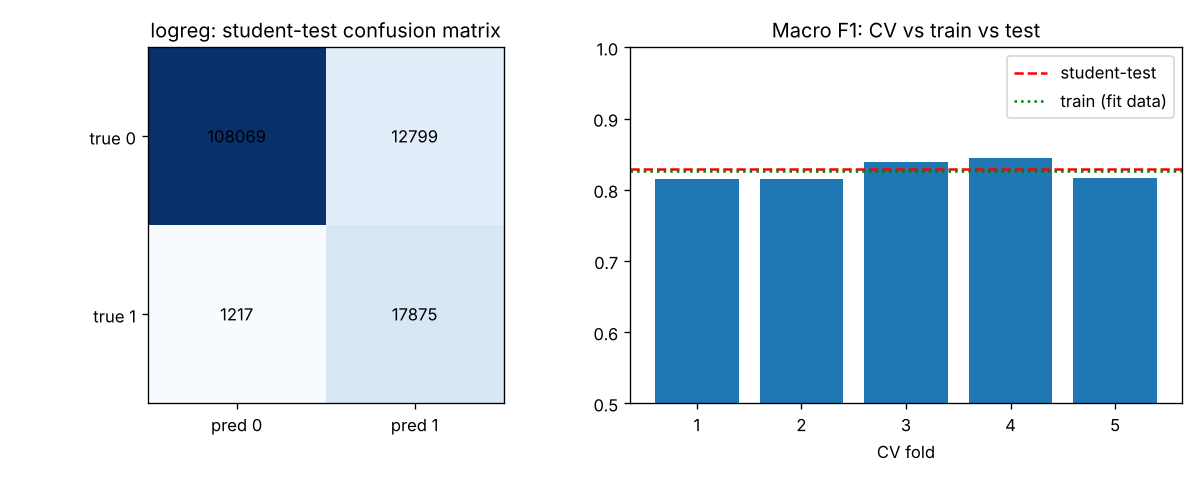

In [6]:
!python plot_results.py logreg
from IPython.display import Image
Image('../results/plots/logreg_diagnostics.png')

## Step 7 — Comparison with all 5 models
**What we say:** The same pipeline, the same features and the same evaluation are used for all five models (Logistic Regression, Random Forest, KNN, LightGBM, MLP), so the comparison is fair. The table is sorted by student_test Top-1 accuracy.

In [7]:
from train_models import comparison_table
comparison_table()

,model,family,cv_macro_f1_mean,cv_macro_f1_std,train_macro_f1,test_macro_f1,test_precision,test_recall,test_log_loss,test_top1_accuracy,train_time_s,inference_time_s
2,lgbm_tuned,Boosting (Bayesian-tuned),0.913226,0.017545,0.933301,0.918469,0.869194,0.848890,0.091774,0.863727,18.340475,1.628193
1,lgbm,Boosting,0.888708,0.017883,0.900048,0.889723,0.710384,0.954955,0.141915,0.860386,10.324093,0.541689
4,mlp,Neural network,0.907300,0.017159,0.914204,0.915676,0.867549,0.840876,0.099219,0.856472,21.219929,0.051044
5,rf,Ensemble (bagging),0.894289,0.019878,0.896987,0.897437,0.736392,0.942437,0.139501,0.854906,24.439006,0.215294
0,knn,Instance-based,0.900836,0.013868,1.000000,0.906916,0.852346,0.825739,0.146993,0.848539,0.873077,49.704447
3,logreg,Linear / probabilistic,0.826067,0.012961,0.825726,0.828732,0.582741,0.936256,0.227736,0.847860,7.477051,0.018992
